Training data: (40000, 3072)
Testing data: (10000, 3072)
Epoch 1/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.3174 - loss: 1.9098
Epoch 2/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3874 - loss: 1.7402
Epoch 3/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4148 - loss: 1.6684
Epoch 4/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4317 - loss: 1.6165
Epoch 5/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4423 - loss: 1.5790
Epoch 6/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4579 - loss: 1.5477
Epoch 7/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4643 - loss: 1.5230
Epoch 8/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4764 - loss: 1.4996
Epoch 9/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.4796 - loss: 1.4764
Epoch 10/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.4864 - loss: 1.4579
Epoch 11/11
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accur

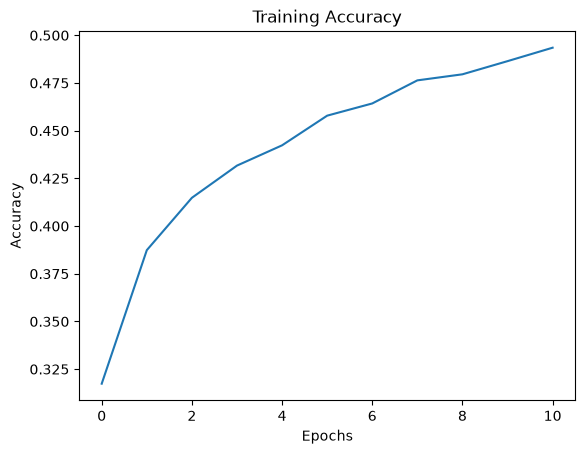

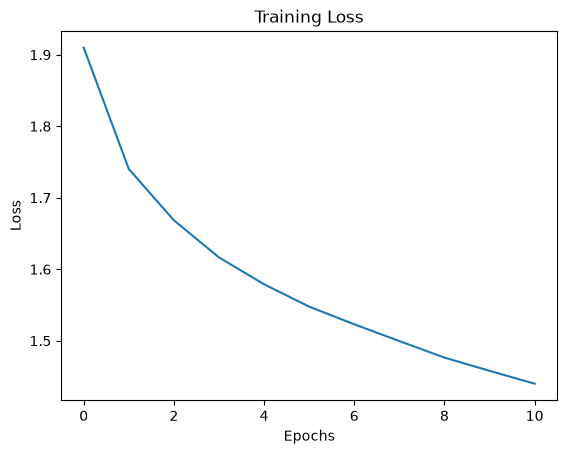

In [1]:

# 1. Import libraries
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# 2. Load local CIFAR-10 dataset
data = pd.read_csv("cifar-10.csv")

# 3. Separate images and labels
X = data.drop("label", axis=1).values
y = data["label"].values

# 4. Normalize pixel values
X = X / 255.0

# 5. Split into training and testing data
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

# 6. Define FNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3072,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# 7. Compile model using SGD
model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 8. Train model
history = model.fit(x_train, y_train, epochs=11)

# 9. Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", accuracy * 100)

# 10. Plot training accuracy
plt.plot(history.history['accuracy'])
plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.show()

# 11. Plot training loss
plt.plot(history.history['loss'])
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()


Let's understand this from the beginning. Don't worry about memorising the code yet. First, understand what we are doing, why we are doing it, and how CIFAR-10 is different from your previous practicals.
1. What is the aim of this practical?
Your practical question asks you to implement a Feedforward Neural Network (FNN) using TensorFlow and Keras.

Our aim is:
1. Give the computer images of objects.
2. Train a neural network to recognise those objects.
3. Test whether the network can correctly identify new images.
4. Display how well the model learned using graphs.
For example, we give the model an image of a cat. It should predict:









Input: Image of a cat

Expected prediction: Cat

Actual model output: One of the 10 classes


This is called image classification.
2. What is an FNN?
FNN stands for Feedforward Neural Network.

Think of it as a system that receives information, processes it and gives an answer.
How an FNN works
Input layer

Receives image pixel values


Hidden layer

128 neurons learn patterns


Output layer

Predicts one of 10 classes


The important thing is that information moves in one direction:

Input → Hidden layer → Output

That's why it is called Feedforward.
3. What were we doing in the previous practicals?
You previously worked with two datasets.









Practical 1A – MNIST

We trained a neural network to recognise handwritten digits from 0 to 9.
- Image size: 28 × 28
- Grayscale images
- 784 input values
- 10 output classes












Practical 1B – Fashion MNIST

We trained a neural network to recognise clothing items.
- Image size: 28 × 28
- Grayscale images
- 784 input values
- 10 output classes












Current implementation – CIFAR-10

We train a neural network to recognise objects such as cats, dogs, cars and airplanes.
- Image size: 32 × 32
- RGB colour images
- 3072 input values
- 10 output classes



The main difference: The previous practicals used 784 input values per image. CIFAR-10 uses 3072 because it has colour images.

The basic FNN training process is almost the same.
4. Now let's understand our CIFAR-10 code step by step
I'll explain each section of the code and what happens behind the scenes.
Step 1 – Import libraries
import pandas as pdimport tensorflow as tfimport matplotlib.pyplot as pltfrom sklearn.model_selection import train_test_split



We import four libraries.
Library	Why do we need it?
Pandas	To read our CSV dataset
TensorFlow	To create and train our neural network
Matplotlib	To draw graphs
train_test_split	To divide data into training and testing sets

Think of libraries as ready-made tools that help us perform tasks.
Step 2 – Load the dataset
data = pd.read_csv("cifar-10.csv")



What is happening here?
- Our CIFAR-10 dataset is stored in a CSV file.
- pd.read_csv() reads that file.
- The complete dataset is stored inside the variable data.
Your CSV contains columns like:
pixel_0, pixel_1, pixel_2, ... pixel_3071, label


Every row represents one image.
Step 3 – Separate images and labels
X = data.drop("label", axis=1).valuesy = data["label"].values



This is one of the most important steps.

Imagine we have a question paper and its answer key.
- X = Questions (images given to the model).
- y = Correct answers (actual image classes).
In our dataset:
- X contains 3072 pixel values.
- y contains the correct category of each image.
Why are we separating them?

Because we want the model to learn from the images (X) and compare its predictions with the correct answers (y).

Remember:
- Capital X = Input images.
- Small y = Actual labels.
Step 4 – Normalize pixel values
X = X / 255.0



What is normalization?

Each pixel has a value between 0 and 255.
- 0 = No intensity.
- 255 = Maximum intensity.
We divide every pixel value by 255 to convert it into a range of 0 to 1.

For example:
Original pixel	After normalization
0	0.0
128	0.502
255	1.0

Why?

It makes the input values smaller and helps the neural network train more effectively.
Step 5 – Split training and testing data
x_train, x_test, y_train, y_test = train_test_split(    X, y, test_size=0.2, random_state=42)



We divide our dataset into two parts.
Example: 60,000 images




80% Training

48,000
Images to learn from


20% Testing

12,000
Images to evaluate on



- Training data teaches the model.
- Testing data checks how well the model learned.
random_state=42 makes the random split reproducible, so running the code again gives the same split.
Step 6 – Define the FNN model
model = tf.keras.Sequential([    tf.keras.layers.Input(shape=(3072,)),    tf.keras.layers.Dense(128, activation='relu'),    tf.keras.layers.Dense(10, activation='softmax')])



This is the actual neural network.

Let's understand each layer.

A. Input layer
tf.keras.layers.Input(shape=(3072,))



Why 3072?

CIFAR-10 images are 32 × 32 pixels and have 3 colour channels.
\[
32 \times 32 \times 3 = 3072
\]

So the model receives 3072 values for every image.

B. Hidden layer
tf.keras.layers.Dense(128, activation='relu')



- Dense(128) means 128 neurons.
- relu is an activation function.
- These neurons learn patterns from the pixel values.
C. Output layer
tf.keras.layers.Dense(10, activation='softmax')



Why 10?

Because CIFAR-10 has 10 categories:
1. Airplane
2. Automobile
3. Bird
4. Cat
5. Deer
6. Dog
7. Frog
8. Horse
9. Ship
10. Truck
Softmax gives a probability for each category. The model chooses the category with the highest probability.
Step 7 – Compile the model
model.compile(    optimizer='sgd',    loss='sparse_categorical_crossentropy',    metrics=['accuracy'])



Before training, we need to configure the model.

There are three important things:
Term	Simple meaning
SGD	Method used to update model weights
Loss	Measures how wrong the prediction is
Accuracy	Measures how many predictions are correct

SGD stands for Stochastic Gradient Descent.

It helps the neural network improve its predictions by adjusting its weights during training.
Step 8 – Train the model
history = model.fit(x_train, y_train, epochs=11)



This is where actual learning happens!
- x_train = Training images.
- y_train = Correct answers.
- epochs=11 = The model goes through the training dataset 11 times.
- history = Stores training accuracy and loss for every epoch.
For example:
Epoch 1/11
Epoch 2/11
Epoch 3/11
...
Epoch 11/11


The model tries to improve its predictions in each epoch.
Step 9 – Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)print("Test Accuracy:", accuracy * 100)



Now we give the model images it did not use for training.

We check how accurately it identifies them.

For example, if accuracy is 0.45:
\[
0.45 \times 100 = 45\%
\]

This means the model correctly classified approximately 45% of the test images.
Step 10 – Plot training accuracy
plt.plot(history.history['accuracy'])plt.title("Training Accuracy")plt.xlabel("Epochs")plt.ylabel("Accuracy")plt.show()



This graph shows how the model's training accuracy changes over 11 epochs.

Usually, accuracy should increase as the model learns.
Step 11 – Plot training loss
plt.plot(history.history['loss'])plt.title("Training Loss")plt.xlabel("Epochs")plt.ylabel("Loss")plt.show()



This graph shows how much error the model makes during training.

Usually, loss should decrease as the model improves.

5. What is the difference between the previous code and current code?
This is important because you will notice that most of the code is repeated.
Step	Previous MNIST / Fashion MNIST	Current CIFAR-10
Dataset	Digits / Clothes	Objects
Image size	28 × 28	32 × 32
Input values	784	3072
Image type	Grayscale	RGB
CSV loading	Often separate train/test CSVs	One CSV in our current code
Data splitting	Already provided separately	We split using train_test_split
Hidden layer	128 neurons	128 neurons
Output layer	10 neurons	10 neurons
Optimizer	SGD	SGD
Epochs	11	11

The most important difference in the code is the dataset loading and input size. The model training process remains almost identical.
6. Quick viva questions
Try to understand these answers because your examiner may ask them.
1. What is FNN?
   Feedforward Neural Network is a neural network in which information moves from input to output in one direction.
2. What is CIFAR-10?
   A dataset containing 60,000 colour images divided into 10 classes.
3. Why do we use 3072 input neurons?
   Because each image has 32 × 32 × 3 = 3072 pixel values.
4. What is ReLU?
   An activation function that converts negative values into zero and keeps positive values.
5. What is Softmax?
   An activation function that converts output values into probabilities for 10 classes.
6. What is SGD?
   Stochastic Gradient Descent, an optimizer used to update model weights.
7. What is an epoch?
   One complete pass through the training dataset.
8. Why do we normalize data?
   To convert pixel values from 0–255 into 0–1.
9. What is loss?
   It measures the error made by the model.
10. What is accuracy?
    It measures the percentage of correct predictions.

7. Test your understanding
Let's check whether you've understood the basic concepts. Try answering these three questions without looking above.
1. Why do we use 3072 input values for CIFAR-10?

28 × 28 pixels

32 × 32 × 3 colour channels

10 output classes



2. What is the purpose of the hidden layer with 128 neurons?

To learn patterns from images

To load the CSV file

To plot accuracy



3. What is the purpose of test data?

To train the model again

To check how well the model performs on unseen data

To normalize images


Check answers
My advice: First understand the flow — Load data → Separate X and y → Normalize → Split → Create model → Compile → Train → Evaluate → Plot. Once you understand this sequence, the practical becomes much easier to remember.